In [5]:
import os
os.environ["PYTENSOR_FLAGS"] = "cxx="

import pandas as pd
from pymc_marketing import clv
from pymc_marketing.clv.utils import rfm_train_test_split

tx = pd.read_parquet("../data/marts/clv_daily_transactions.parquet")
tx["purchase_date"] = pd.to_datetime(tx["purchase_date"])

tx.info()
tx.head()

<class 'pandas.DataFrame'>
RangeIndex: 32675 entries, 0 to 32674
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype        
---  ------         --------------  -----        
 0   customer_id    32675 non-null  str          
 1   purchase_date  32675 non-null  datetime64[s]
 2   amount         32675 non-null  object       
dtypes: datetime64[s](1), object(1), str(1)
memory usage: 925.5+ KB


,customer_id,purchase_date,amount
0,13098,2011-04-06,1722.0200
1,12347,2011-04-07,636.2500
2,15874,2011-04-08,1163.7500
3,13078,2011-04-08,280.6800
4,15311,2011-04-10,587.8200


In [6]:
CAL_END = "2011-06-09"   # train
OBS_END = "2011-12-09"   # test

rfm = rfm_train_test_split(
    tx,
    customer_id_col="customer_id",
    datetime_col="purchase_date",
    monetary_value_col="amount",
    train_period_end=CAL_END,
    test_period_end=OBS_END,
    time_unit="D",
)

print(len(rfm), "customers")
rfm.head()

4927 customers


,customer_id,frequency,recency,T,monetary_value,test_frequency,test_monetary_value,test_T
0,12346,1.0,118.0,464.0,142.3100,0.0,0,183.0
1,12347,4.0,221.0,221.0,551.4875,3.0,701.35,183.0
2,12348,3.0,190.0,255.0,389.0800,1.0,270.0,183.0
3,12349,1.0,182.0,406.0,1152.6200,1.0,1457.55,183.0
4,12350,0.0,0.0,127.0,0.0000,0.0,0,183.0


In [7]:
# สัดส่วนลูกค้าที่ไม่เคยซื้อซ้ำในช่วง calibration
print("one-time buyers:", round((rfm["frequency"] == 0).mean() * 100, 1), "%")

# sanity check: recency ต้องไม่เกิน T เสมอ (ควรได้ 0)
print("recency > T:", (rfm["recency"] > rfm["T"]).sum())

# assumption ของ Gamma-Gamma: ความถี่กับยอดต่อครั้งต้องไม่สัมพันธ์กัน
repeat = rfm[rfm["frequency"] > 0]
repeat[["frequency", "monetary_value"]].corr()

one-time buyers: 32.5 %
recency > T: 0


,frequency,monetary_value
frequency,1.00000,0.13062
monetary_value,0.13062,1.00000


In [8]:
print("customers with T = 0:", (rfm["T"] == 0).sum())

rfm = rfm[rfm["T"] > 0].copy()          # ตัดลูกค้าที่ซื้อครั้งแรกวันตัดข้อมูล
cal = rfm[["customer_id", "frequency", "recency", "T"]]

bgm = clv.BetaGeoModel()
bgm.fit(data=cal, method="map")
bgm.fit_summary()

customers with T = 0: 3


E:\Data_Analytic\Online Retail II\.venv\Lib\site-packages\pymc_marketing\model_builder.py:881: FutureWarning: `find_MAP` will return an `InferenceData` instead of a dict in a future release. Pass `return_inferencedata=True` to adopt the new behavior now.
  map_res = pm.find_MAP(model=model, **kwargs)
E:\Data_Analytic\Online Retail II\.venv\Lib\site-packages\pymc_marketing\model_builder.py:881: FutureWarning: `find_MAP` will jitter its initial point by default in a future release. Pass `jitter=True` to adopt that now, or `jitter=False` to keep the current behavior.
  map_res = pm.find_MAP(model=model, **kwargs)


Output()

alpha            61.219029
phi_dropout       0.048968
kappa_dropout     2.803707
r                 0.648997
a                 0.137293
b                 2.666414
Name: value, dtype: float64

In [9]:
import numpy as np

def to_series(x):
    """แปลงผลจาก model (xarray) เป็น pandas Series ต่อลูกค้า"""
    dims = [d for d in ("chain", "draw") if d in x.dims]
    return x.mean(dim=dims).to_series()

HOLDOUT_DAYS = (pd.Timestamp(OBS_END) - pd.Timestamp(CAL_END)).days

pred = to_series(bgm.expected_purchases(future_t=HOLDOUT_DAYS)).rename("predicted")

eval_df = rfm.set_index("customer_id").join(pred)
eval_df["baseline"] = eval_df["frequency"] / eval_df["T"] * HOLDOUT_DAYS   # อัตราซื้อในอดีต × จำนวนวัน

summary = pd.DataFrame({
    "total": eval_df[["test_frequency", "predicted", "baseline"]].sum(),
    "MAE":   [np.nan,
              (eval_df["predicted"] - eval_df["test_frequency"]).abs().mean(),
              (eval_df["baseline"]  - eval_df["test_frequency"]).abs().mean()],
}, index=["test_frequency", "predicted", "baseline"])
summary.round(2)

,total,MAE
test_frequency,7693.00,NaN
predicted,7601.99,1.04
baseline,8072.15,1.09


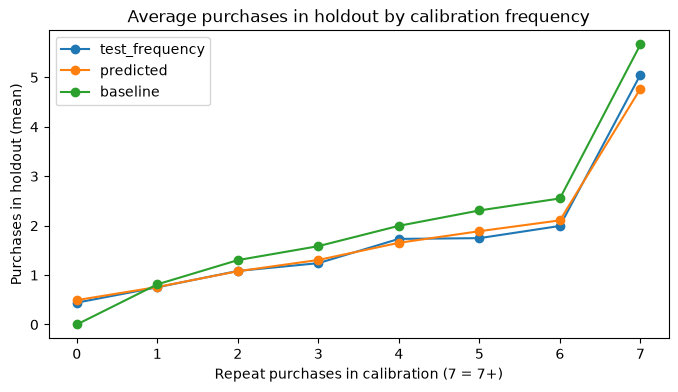

,test_frequency,predicted,baseline
freq_bucket,,,
0.0,0.44,0.49,0.00
1.0,0.75,0.76,0.81
2.0,1.08,1.08,1.30
3.0,1.24,1.31,1.59
4.0,1.73,1.65,2.00
5.0,1.75,1.89,2.31
6.0,1.99,2.11,2.55
7.0,5.06,4.77,5.67


In [10]:
import matplotlib.pyplot as plt

eval_df["freq_bucket"] = eval_df["frequency"].clip(upper=7)   # 7 = 7 ครั้งขึ้นไป
check = eval_df.groupby("freq_bucket")[["test_frequency", "predicted", "baseline"]].mean()

check.plot(marker="o", figsize=(8, 4),
           title="Average purchases in holdout by calibration frequency")
plt.xlabel("Repeat purchases in calibration (7 = 7+)")
plt.ylabel("Purchases in holdout (mean)")
plt.show()
check.round(2)

In [11]:
from scipy.stats import spearmanr

actual = eval_df["test_frequency"]
results = {}
for col in ["predicted", "baseline"]:
    err = eval_df[col] - actual
    results[col] = {
        "total_bias_%": 100 * (eval_df[col].sum() - actual.sum()) / actual.sum(),
        "MAE":          err.abs().mean(),
        "RMSE":         np.sqrt((err ** 2).mean()),
        "spearman":     spearmanr(eval_df[col], actual).correlation,
    }
pd.DataFrame(results).round(3)

,predicted,baseline
total_bias_%,-1.183,4.929
MAE,1.039,1.086
RMSE,1.769,1.928
spearman,0.623,0.576


In [12]:
eval_df.assign(
    err_model=(eval_df["predicted"] - actual).abs(),
    err_baseline=(eval_df["baseline"] - actual).abs(),
).groupby("freq_bucket")[["err_model", "err_baseline"]].mean().round(2)

,err_model,err_baseline
freq_bucket,,
0.0,0.61,0.44
1.0,0.82,0.86
2.0,0.93,1.07
3.0,1.03,1.19
4.0,1.31,1.42
5.0,1.20,1.42
6.0,1.16,1.33
7.0,2.08,2.35


In [13]:
from pymc_marketing.clv.utils import rfm_summary

full = rfm_summary(
    tx,
    customer_id_col="customer_id",
    datetime_col="purchase_date",
    monetary_value_col="amount",
    observation_period_end=OBS_END,
    time_unit="D",
)
full = full[full["T"] > 0].copy()

bgm_full = clv.BetaGeoModel()
bgm_full.fit(data=full[["customer_id", "frequency", "recency", "T"]], method="map")

full = full.set_index("customer_id")
full["p_alive"]        = to_series(bgm_full.expected_probability_alive())
full["exp_purch_12m"]  = to_series(bgm_full.expected_purchases(future_t=365))

print(len(full), "customers")
full[["frequency", "recency", "T", "p_alive", "exp_purch_12m"]].describe().round(2)

E:\Data_Analytic\Online Retail II\.venv\Lib\site-packages\pymc_marketing\model_builder.py:881: FutureWarning: `find_MAP` will return an `InferenceData` instead of a dict in a future release. Pass `return_inferencedata=True` to adopt the new behavior now.
  map_res = pm.find_MAP(model=model, **kwargs)
E:\Data_Analytic\Online Retail II\.venv\Lib\site-packages\pymc_marketing\model_builder.py:881: FutureWarning: `find_MAP` will jitter its initial point by default in a future release. Pass `jitter=True` to adopt that now, or `jitter=False` to keep the current behavior.
  map_res = pm.find_MAP(model=model, **kwargs)


Output()

5830 customers


,frequency,recency,T,p_alive,exp_purch_12m
count,5830.00,5830.00,5830.00,5830.00,5830.00
mean,4.60,273.87,473.64,0.91,3.14
std,9.87,258.53,223.14,0.17,4.79
min,0.00,0.00,1.00,0.00,0.00
25%,0.00,0.00,311.00,0.93,0.70
50%,2.00,223.00,529.00,0.98,1.79
75%,5.00,512.00,666.00,1.00,3.85
max,244.00,738.00,738.00,1.00,109.55


In [14]:
full["days_since_last"] = full["T"] - full["recency"]

# ลูกค้าซื้อบ่อย แต่หายไปนาน → p_alive ควรต่ำ
print(full.query("frequency >= 10")
          .sort_values("days_since_last", ascending=False)
          [["frequency", "recency", "T", "days_since_last", "p_alive"]].head(10).round(3))

# ลูกค้าซื้อครั้งเดียว → p_alive = 1 ทุกคน?
full.groupby(full["frequency"] == 0)["p_alive"].describe().round(3)

             frequency  recency      T  days_since_last  p_alive
customer_id                                                     
17448             12.0    116.0  645.0            529.0    0.000
15633             12.0    222.0  731.0            509.0    0.000
15015             10.0    224.0  725.0            501.0    0.002
16742             12.0    231.0  723.0            492.0    0.000
13446             10.0    233.0  663.0            430.0    0.007
12835             36.0    309.0  736.0            427.0    0.000
14590             18.0    308.0  732.0            424.0    0.000
14648             12.0    313.0  729.0            416.0    0.010
13206             11.0    332.0  732.0            400.0    0.032
17241             10.0    277.0  662.0            385.0    0.031


,count,mean,std,min,25%,50%,75%,max
frequency,,,,,,,,
False,4170.0,0.875,0.191,0.0,0.872,0.953,0.979,0.999
True,1660.0,1.000,0.000,1.0,1.000,1.000,1.000,1.000


In [15]:
mbgm = clv.ModifiedBetaGeoModel()
mbgm.fit(data=cal, method="map")

eval_df["pred_mbg"]    = to_series(mbgm.expected_purchases(future_t=HOLDOUT_DAYS))
eval_df["p_alive_bg"]  = to_series(bgm.expected_probability_alive())
eval_df["p_alive_mbg"] = to_series(mbgm.expected_probability_alive())

# ความแม่นยำบน holdout
actual = eval_df["test_frequency"]
comp = {}
for col in ["predicted", "pred_mbg", "baseline"]:
    err = eval_df[col] - actual
    comp[col] = {
        "total_bias_%": 100 * (eval_df[col].sum() - actual.sum()) / actual.sum(),
        "MAE": err.abs().mean(),
    }
display(pd.DataFrame(comp).round(3))

# p_alive ของลูกค้าซื้อครั้งเดียว: เดิม vs ใหม่
display(eval_df[eval_df["frequency"] == 0][["p_alive_bg", "p_alive_mbg"]].describe().round(3))

E:\Data_Analytic\Online Retail II\.venv\Lib\site-packages\pymc_marketing\model_builder.py:881: FutureWarning: `find_MAP` will return an `InferenceData` instead of a dict in a future release. Pass `return_inferencedata=True` to adopt the new behavior now.
  map_res = pm.find_MAP(model=model, **kwargs)
E:\Data_Analytic\Online Retail II\.venv\Lib\site-packages\pymc_marketing\model_builder.py:881: FutureWarning: `find_MAP` will jitter its initial point by default in a future release. Pass `jitter=True` to adopt that now, or `jitter=False` to keep the current behavior.
  map_res = pm.find_MAP(model=model, **kwargs)


Output()

,predicted,pred_mbg,baseline
total_bias_%,-1.183,-0.703,4.929
MAE,1.039,1.043,1.086


,p_alive_bg,p_alive_mbg
count,1597.0,1597.000
mean,1.0,0.899
std,0.0,0.032
min,1.0,0.846
25%,1.0,0.871
50%,1.0,0.900
75%,1.0,0.924
max,1.0,0.963


In [16]:
full_in = full.reset_index()

# Refit MBG/NBD ด้วยข้อมูลทั้งหมด
mbgm_full = clv.ModifiedBetaGeoModel()
mbgm_full.fit(data=full_in[["customer_id", "frequency", "recency", "T"]], method="map")
full["p_alive"]       = to_series(mbgm_full.expected_probability_alive())
full["exp_purch_12m"] = to_series(mbgm_full.expected_purchases(future_t=365))

# Gamma-Gamma: fit เฉพาะลูกค้าที่ซื้อซ้ำ
repeat_in = full_in[(full_in["frequency"] > 0) & (full_in["monetary_value"] > 0)]
ggm = clv.GammaGammaModel()
ggm.fit(data=repeat_in[["customer_id", "frequency", "monetary_value"]], method="map")

# ยอดต่อครั้งที่คาดไว้ + CLV 12 เดือน (ลูกค้าทุกคน)
clv_in = full_in[["customer_id", "frequency", "recency", "T", "monetary_value"]]
full["exp_spend"] = to_series(ggm.expected_customer_spend(data=clv_in))
full["clv_12m"]   = to_series(ggm.expected_customer_lifetime_value(
    transaction_model=mbgm_full,
    data=clv_in,
    future_t=12,          # หน่วยเป็น "เดือน" เสมอ
    discount_rate=0.01,   # 1% ต่อเดือน
    time_unit="D",        # ข้อมูลเป็นรายวัน
))

full[["p_alive", "exp_purch_12m", "exp_spend", "clv_12m"]].describe().round(2)

E:\Data_Analytic\Online Retail II\.venv\Lib\site-packages\pymc_marketing\model_builder.py:881: FutureWarning: `find_MAP` will return an `InferenceData` instead of a dict in a future release. Pass `return_inferencedata=True` to adopt the new behavior now.
  map_res = pm.find_MAP(model=model, **kwargs)
E:\Data_Analytic\Online Retail II\.venv\Lib\site-packages\pymc_marketing\model_builder.py:881: FutureWarning: `find_MAP` will jitter its initial point by default in a future release. Pass `jitter=True` to adopt that now, or `jitter=False` to keep the current behavior.
  map_res = pm.find_MAP(model=model, **kwargs)


Output()

E:\Data_Analytic\Online Retail II\.venv\Lib\site-packages\pymc_marketing\model_builder.py:881: FutureWarning: `find_MAP` will return an `InferenceData` instead of a dict in a future release. Pass `return_inferencedata=True` to adopt the new behavior now.
  map_res = pm.find_MAP(model=model, **kwargs)
E:\Data_Analytic\Online Retail II\.venv\Lib\site-packages\pymc_marketing\model_builder.py:881: FutureWarning: `find_MAP` will jitter its initial point by default in a future release. Pass `jitter=True` to adopt that now, or `jitter=False` to keep the current behavior.
  map_res = pm.find_MAP(model=model, **kwargs)


Output()

,p_alive,exp_purch_12m,exp_spend,clv_12m
count,5830.00,5830.00,5830.00,5830.00
mean,0.88,3.14,400.73,1397.06
std,0.16,4.73,407.33,6043.56
min,0.00,0.00,18.76,0.00
25%,0.85,0.74,241.81,200.66
50%,0.94,1.83,398.48,527.09
75%,0.97,3.85,417.96,1223.94
max,1.00,108.29,17361.75,241271.66


In [17]:
# เทียบ CLV 12 เดือนข้างหน้า กับยอดขายจริง 12 เดือนที่ผ่านมา
last12 = tx[tx["purchase_date"] > pd.Timestamp(OBS_END) - pd.DateOffset(years=1)]
print("actual sales, last 12m :", f"{last12['amount'].sum():,.0f}")
print("predicted CLV, next 12m:", f"{full['clv_12m'].sum():,.0f}")

# ลูกค้า CLV สูงสุด 10 คน
display(full.sort_values("clv_12m", ascending=False)
            [["frequency", "p_alive", "exp_purch_12m", "exp_spend", "clv_12m"]].head(10).round(2))

# top 20% สร้าง CLV กี่ %
cut = full["clv_12m"].quantile(0.8)
print("top 20% share of CLV:",
      round(100 * full.loc[full["clv_12m"] >= cut, "clv_12m"].sum() / full["clv_12m"].sum(), 1), "%")

full.reset_index().to_parquet("../data/marts/customer_clv.parquet", index=False)

actual sales, last 12m : 8,003,872
predicted CLV, next 12m: 8,144,866


,frequency,p_alive,exp_purch_12m,exp_spend,clv_12m
customer_id,,,,,
18102,66.0,1.00,29.50,8709.09,241271.66
14646,90.0,1.00,40.17,5710.23,215396.74
17450,29.0,0.99,20.64,6651.82,128975.81
14156,115.0,1.00,51.03,2566.40,122983.27
14911,244.0,1.00,108.29,1026.35,104372.76
14096,16.0,0.99,33.59,3283.86,103670.86
12415,17.0,0.99,10.44,8178.65,80183.63
13694,82.0,1.00,36.70,2313.46,79723.70
17511,50.0,1.00,22.44,3180.71,67014.76


top 20% share of CLV: 71.8 %
